In [1]:
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
votacao = pd.read_csv('votacao_secao_2026_BR\\votacao_secao_2026_BR.csv', encoding='latin1', sep=';')

In [3]:
votacao[votacao.NR_TURNO == 1].head(1).T

,0
DT_GERACAO,06/10/2026
HH_GERACAO,14:03:43
ANO_ELEICAO,2026
CD_TIPO_ELEICAO,2
NM_TIPO_ELEICAO,Eleição Ordinária
NR_TURNO,1
CD_ELEICAO,6257
DS_ELEICAO,Eleição Geral Federal 2026
DT_ELEICAO,04/10/2026
TP_ABRANGENCIA,F


In [4]:
vot_mun = votacao[votacao.NR_TURNO == 1].pivot_table(index=['SG_UF','CD_MUNICIPIO','NM_MUNICIPIO'], columns='NR_VOTAVEL', values='QT_VOTOS', aggfunc='sum', margins=True).reset_index()
vot_mun

NR_VOTAVEL,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,13,14,16,21,22,27,28,29,30,35,55,70,80,95,96,All
0,AC,1007,BUJARI,2394.0,68.0,3.0,3.0,5531.0,3.0,NaN,2.0,3.0,NaN,133.0,165.0,3.0,98.0,251.0,8657
1,AC,1015,CAPIXABA,1732.0,77.0,NaN,2.0,4227.0,1.0,NaN,NaN,16.0,NaN,134.0,108.0,1.0,56.0,159.0,6513
2,AC,1023,PORTO ACRE,2658.0,113.0,NaN,6.0,7926.0,NaN,1.0,NaN,22.0,1.0,169.0,228.0,5.0,124.0,356.0,11609
3,AC,1031,SANTA ROSA DO PURUS,1384.0,17.0,NaN,1.0,1258.0,1.0,NaN,NaN,2.0,NaN,24.0,55.0,NaN,12.0,130.0,2884
4,AC,1040,MARECHAL THAUMATURGO,3365.0,43.0,NaN,2.0,5369.0,2.0,NaN,2.0,3.0,NaN,102.0,189.0,1.0,48.0,226.0,9352
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5712,ZZ,99473,BAREIN,17.0,1.0,NaN,NaN,27.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,2.0,49
5713,ZZ,99490,ORLANDO,1332.0,228.0,2.0,3.0,6981.0,5.0,NaN,NaN,60.0,5.0,71.0,177.0,4.0,60.0,66.0,8994
5714,ZZ,99503,EDIMBURGO,488.0,21.0,NaN,1.0,139.0,1.0,NaN,1.0,1.0,1.0,9.0,12.0,3.0,8.0,9.0,694
5715,ZZ,99511,MARSELHA,715.0,19.0,3.0,NaN,104.0,1.0,NaN,NaN,6.0,1.0,1.0,13.0,5.0,4.0,3.0,875


In [5]:
vot_uf = votacao[votacao.NR_TURNO == 1].pivot_table(index=['SG_UF',], columns='NR_VOTAVEL', values='QT_VOTOS', aggfunc='sum', margins=True).reset_index()
vot_uf

NR_VOTAVEL,SG_UF,13,14,16,21,22,27,28,29,30,35,55,70,80,95,96,All
0,AC,134770,7980,71,140,302807,215,23,40,573,39,8594,13523,314,5579,13662,488330
1,AL,995459,26851,431,267,735718,636,73,110,1168,246,14198,42427,1345,33712,85787,1938428
2,AM,1046996,35411,457,265,976764,929,82,161,1781,291,28310,77531,1867,24402,39302,2234549
3,AP,212503,11342,132,62,212278,229,17,53,341,49,8304,19057,508,4415,7272,476562
4,BA,5664771,117518,1791,1299,2442585,1676,251,724,6497,625,122705,195451,4649,154936,338123,9053601
5,CE,3555263,107587,1491,783,1756850,1071,177,498,4310,481,45604,140524,3352,103295,189185,5910471
6,DF,675627,46714,828,334,909616,716,57,382,4915,324,85076,45979,2297,25362,33169,1831396
7,ES,850028,53236,638,388,1233194,974,121,245,5873,311,39097,65121,1973,43211,57872,2352282
8,GO,1188880,54105,668,468,2051888,559,107,260,2672,346,472041,53849,2087,45643,98014,3971587
9,MA,2566301,60387,1459,475,1239040,895,345,211,4584,307,50155,84830,1795,46315,103244,4160343


In [6]:
votacao.loc[(votacao.NM_MUNICIPIO == 'RECIFE')]

,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,...,NR_SECAO,CD_CARGO,DS_CARGO,NR_VOTAVEL,NM_VOTAVEL,QT_VOTOS,NR_LOCAL_VOTACAO,SQ_CANDIDATO,NM_LOCAL_VOTACAO,DS_LOCAL_VOTACAO_ENDERECO
563961,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,315,1,Presidente,96,VOTO NULO,7,1350,-1,ESCOLA MUNICIPAL PASTOR MUNGUBA SOBRINHO,"RUA SILVA JARDIM, 145"
563975,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,471,1,Presidente,96,VOTO NULO,10,1694,-1,ESCOLA MUNICIPAL DOM JOSÉ LAMARTINE SOARES,"RUA ALTO DO EUCALIPTO, S/N"
563979,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,5,1,Presidente,96,VOTO NULO,13,1015,-1,ESCOLA MUNICIPAL DARCY RIBEIRO,"RUA ODETE MONTEIRO, N 384"
563986,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,227,1,Presidente,96,VOTO NULO,12,1325,-1,ESCOLA PROFESSORA HELENA PUGÓ,RUA QUINZE DE MARÇO - S/N
563990,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,585,1,Presidente,96,VOTO NULO,21,1970,-1,ESCOLA SENADOR ANTONIO FARIAS,"AVENIDA CAMPO VERDE, 415"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3499147,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,246,1,Presidente,80,SAMARA MARTINS DA SILVA FEITOSA,2,1040,280002538811,COLEGIO SANTA MARIA,"RUA PADRE BERNARDINO PESSOA, 512 BOA VIAGEM"
3499152,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,121,1,Presidente,80,SAMARA MARTINS DA SILVA FEITOSA,1,1295,280002538811,ESCOLA LUIZ DELGADO,"RUA DO HOSPÍCIO, S/N - EM FRENTE AO PARQUE TR..."
3499153,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,304,1,Presidente,80,SAMARA MARTINS DA SILVA FEITOSA,1,1040,280002538811,COLEGIO SANTA MARIA,"RUA PADRE BERNARDINO PESSOA, 512 BOA VIAGEM"
3500102,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,376,1,Presidente,80,SAMARA MARTINS DA SILVA FEITOSA,1,1562,280002538811,ESCOLA CORONEL OTHON,"RUA IDA, S/N"


In [8]:
vot_mun[vot_mun.columns[3:]] = vot_mun[vot_mun.columns[3:]].div(vot_mun.All, axis=0)

In [12]:
mapa = gpd.read_file('BR_Municipios_2021\\BR_Municipios_2021.shp')

In [13]:
mapa_uf = gpd.read_file('BR_UF_2021\\BR_UF_2021.shp')

In [14]:
vot_uf

NR_VOTAVEL,SG_UF,13,14,16,21,22,27,28,29,30,35,55,70,80,95,96,All
0,AC,134770,7980,71,140,302807,215,23,40,573,39,8594,13523,314,5579,13662,488330
1,AL,995459,26851,431,267,735718,636,73,110,1168,246,14198,42427,1345,33712,85787,1938428
2,AM,1046996,35411,457,265,976764,929,82,161,1781,291,28310,77531,1867,24402,39302,2234549
3,AP,212503,11342,132,62,212278,229,17,53,341,49,8304,19057,508,4415,7272,476562
4,BA,5664771,117518,1791,1299,2442585,1676,251,724,6497,625,122705,195451,4649,154936,338123,9053601
5,CE,3555263,107587,1491,783,1756850,1071,177,498,4310,481,45604,140524,3352,103295,189185,5910471
6,DF,675627,46714,828,334,909616,716,57,382,4915,324,85076,45979,2297,25362,33169,1831396
7,ES,850028,53236,638,388,1233194,974,121,245,5873,311,39097,65121,1973,43211,57872,2352282
8,GO,1188880,54105,668,468,2051888,559,107,260,2672,346,472041,53849,2087,45643,98014,3971587
9,MA,2566301,60387,1459,475,1239040,895,345,211,4584,307,50155,84830,1795,46315,103244,4160343


In [15]:
vot_uf[vot_uf.columns[1:]]

NR_VOTAVEL,13,14,16,21,22,27,28,29,30,35,55,70,80,95,96,All
0,134770,7980,71,140,302807,215,23,40,573,39,8594,13523,314,5579,13662,488330
1,995459,26851,431,267,735718,636,73,110,1168,246,14198,42427,1345,33712,85787,1938428
2,1046996,35411,457,265,976764,929,82,161,1781,291,28310,77531,1867,24402,39302,2234549
3,212503,11342,132,62,212278,229,17,53,341,49,8304,19057,508,4415,7272,476562
4,5664771,117518,1791,1299,2442585,1676,251,724,6497,625,122705,195451,4649,154936,338123,9053601
5,3555263,107587,1491,783,1756850,1071,177,498,4310,481,45604,140524,3352,103295,189185,5910471
6,675627,46714,828,334,909616,716,57,382,4915,324,85076,45979,2297,25362,33169,1831396
7,850028,53236,638,388,1233194,974,121,245,5873,311,39097,65121,1973,43211,57872,2352282
8,1188880,54105,668,468,2051888,559,107,260,2672,346,472041,53849,2087,45643,98014,3971587
9,2566301,60387,1459,475,1239040,895,345,211,4584,307,50155,84830,1795,46315,103244,4160343


In [16]:
vot_uf[vot_uf.columns[1:]] = vot_uf[vot_uf.columns[1:]].div(vot_uf.All, axis=0)

In [17]:
mapa.NM_MUN = mapa.NM_MUN.str.upper()

In [18]:
mapa.loc[mapa.NM_MUN=='Ituiutaba']

,CD_MUN,NM_MUN,SIGLA,AREA_KM2,geometry


In [19]:
mapa.head()

,CD_MUN,NM_MUN,SIGLA,AREA_KM2,geometry
0,1100015,ALTA FLORESTA D'OESTE,RO,7067.127,"POLYGON ((-62.19465 -11.82746, -62.19332 -11.8..."
1,1100023,ARIQUEMES,RO,4426.571,"POLYGON ((-62.53648 -9.73222, -62.52765 -9.736..."
2,1100031,CABIXI,RO,1314.352,"POLYGON ((-60.37119 -13.36655, -60.37134 -13.3..."
3,1100049,CACOAL,RO,3793.000,"POLYGON ((-61.0008 -11.29737, -61.00103 -11.39..."
4,1100056,CEREJEIRAS,RO,2783.300,"POLYGON ((-61.49976 -13.00525, -61.49809 -13.0..."


In [24]:
vot_mun.head()

NR_VOTAVEL,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,13,14,16,21,22,27,28,29,30,35,55,70,80,95,96,All
0,AC,1007,BUJARI,0.276539,0.007855,0.000347,0.000347,0.638905,0.000347,NaN,0.000231,0.000347,NaN,0.015363,0.019060,0.000347,0.011320,0.028994,1.0
1,AC,1015,CAPIXABA,0.265930,0.011823,NaN,0.000307,0.649010,0.000154,NaN,NaN,0.002457,NaN,0.020574,0.016582,0.000154,0.008598,0.024413,1.0
2,AC,1023,PORTO ACRE,0.228960,0.009734,NaN,0.000517,0.682746,NaN,0.000086,NaN,0.001895,0.000086,0.014558,0.019640,0.000431,0.010681,0.030666,1.0
3,AC,1031,SANTA ROSA DO PURUS,0.479889,0.005895,NaN,0.000347,0.436200,0.000347,NaN,NaN,0.000693,NaN,0.008322,0.019071,NaN,0.004161,0.045076,1.0
4,AC,1040,MARECHAL THAUMATURGO,0.359816,0.004598,NaN,0.000214,0.574102,0.000214,NaN,0.000214,0.000321,NaN,0.010907,0.020210,0.000107,0.005133,0.024166,1.0


In [21]:
mapa.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   CD_MUN    5572 non-null   str     
 1   NM_MUN    5572 non-null   str     
 2   SIGLA     5572 non-null   str     
 3   AREA_KM2  5572 non-null   float64 
 4   geometry  5572 non-null   geometry
dtypes: float64(1), geometry(1), str(3)
memory usage: 217.8 KB


In [22]:
vot_mun.info()

<class 'pandas.DataFrame'>
RangeIndex: 5717 entries, 0 to 5716
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SG_UF         5717 non-null   str    
 1   CD_MUNICIPIO  5717 non-null   object 
 2   NM_MUNICIPIO  5717 non-null   str    
 3   13            5717 non-null   float64
 4   14            5687 non-null   float64
 5   16            3440 non-null   float64
 6   21            3539 non-null   float64
 7   22            5715 non-null   float64
 8   27            3692 non-null   float64
 9   28            1669 non-null   float64
 10  29            2244 non-null   float64
 11  30            5263 non-null   float64
 12  35            2572 non-null   float64
 13  55            5687 non-null   float64
 14  70            5696 non-null   float64
 15  80            4601 non-null   float64
 16  95            5681 non-null   float64
 17  96            5682 non-null   float64
 18  All           5717 non-null   float64
d

In [29]:
vot_mun

NR_VOTAVEL,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,13,14,16,21,22,27,28,29,30,35,55,70,80,95,96,All
0,AC,1007,BUJARI,0.276539,0.007855,0.000347,0.000347,0.638905,0.000347,NaN,0.000231,0.000347,NaN,0.015363,0.019060,0.000347,0.011320,0.028994,1.0
1,AC,1015,CAPIXABA,0.265930,0.011823,NaN,0.000307,0.649010,0.000154,NaN,NaN,0.002457,NaN,0.020574,0.016582,0.000154,0.008598,0.024413,1.0
2,AC,1023,PORTO ACRE,0.228960,0.009734,NaN,0.000517,0.682746,NaN,0.000086,NaN,0.001895,0.000086,0.014558,0.019640,0.000431,0.010681,0.030666,1.0
3,AC,1031,SANTA ROSA DO PURUS,0.479889,0.005895,NaN,0.000347,0.436200,0.000347,NaN,NaN,0.000693,NaN,0.008322,0.019071,NaN,0.004161,0.045076,1.0
4,AC,1040,MARECHAL THAUMATURGO,0.359816,0.004598,NaN,0.000214,0.574102,0.000214,NaN,0.000214,0.000321,NaN,0.010907,0.020210,0.000107,0.005133,0.024166,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5712,ZZ,99473,BAREIN,0.346939,0.020408,NaN,NaN,0.551020,NaN,NaN,NaN,NaN,NaN,NaN,0.040816,NaN,NaN,0.040816,1.0
5713,ZZ,99490,ORLANDO,0.148099,0.025350,0.000222,0.000334,0.776184,0.000556,NaN,NaN,0.006671,0.000556,0.007894,0.019680,0.000445,0.006671,0.007338,1.0
5714,ZZ,99503,EDIMBURGO,0.703170,0.030259,NaN,0.001441,0.200288,0.001441,NaN,0.001441,0.001441,0.001441,0.012968,0.017291,0.004323,0.011527,0.012968,1.0
5715,ZZ,99511,MARSELHA,0.817143,0.021714,0.003429,NaN,0.118857,0.001143,NaN,NaN,0.006857,0.001143,0.001143,0.014857,0.005714,0.004571,0.003429,1.0


In [31]:
mapa_vot = mapa.merge(vot_mun, left_on=['SIGLA', 'NM_MUN'], right_on=['SG_UF', 'NM_MUNICIPIO'])
mapa_vot

,CD_MUN,NM_MUN,SIGLA,AREA_KM2,geometry,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,13,14,...,28,29,30,35,55,70,80,95,96,All
0,1100023,ARIQUEMES,RO,4426.571,"POLYGON ((-62.53648 -9.73222, -62.52765 -9.736...",RO,78,ARIQUEMES,0.178560,0.019313,...,0.000054,0.000090,0.001329,NaN,0.010600,0.021343,0.000593,0.008857,0.010312,1.0
1,1100031,CABIXI,RO,1314.352,"POLYGON ((-60.37119 -13.36655, -60.37134 -13.3...",RO,450,CABIXI,0.264676,0.009615,...,0.000253,NaN,0.001265,NaN,0.012399,0.020749,0.000759,0.008350,0.012146,1.0
2,1100049,CACOAL,RO,3793.000,"POLYGON ((-61.0008 -11.29737, -61.00103 -11.39...",RO,94,CACOAL,0.219854,0.021587,...,0.000091,0.000036,0.001726,0.000036,0.022805,0.024876,0.000545,0.009576,0.012465,1.0
3,1100056,CEREJEIRAS,RO,2783.300,"POLYGON ((-61.49976 -13.00525, -61.49809 -13.0...",RO,272,CEREJEIRAS,0.173374,0.014984,...,NaN,NaN,0.001345,0.000192,0.011622,0.017770,0.000288,0.006339,0.010566,1.0
4,1100064,COLORADO DO OESTE,RO,1451.060,"POLYGON ((-60.50475 -12.96672, -60.50475 -12.9...",RO,230,COLORADO DO OESTE,0.219572,0.014290,...,0.000099,0.000197,0.001971,NaN,0.017246,0.021780,0.000986,0.014191,0.013600,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5501,5222005,VIANÓPOLIS,GO,954.115,"POLYGON ((-48.42801 -16.62789, -48.42803 -16.6...",GO,96415,VIANÓPOLIS,0.215467,0.008210,...,NaN,0.000111,0.000555,NaN,0.122157,0.008765,0.000555,0.008876,0.024742,1.0
5502,5222054,VICENTINÓPOLIS,GO,733.794,"POLYGON ((-49.8474 -17.57796, -49.84719 -17.57...",GO,96571,VICENTINÓPOLIS,0.334838,0.012504,...,NaN,NaN,0.000347,0.000174,0.069642,0.013894,0.000347,0.010073,0.027614,1.0
5503,5222203,VILA BOA,GO,1052.593,"POLYGON ((-47.10998 -14.67195, -47.10994 -14.6...",GO,93289,VILA BOA,0.472615,0.009990,...,NaN,NaN,0.000344,0.000344,0.156734,0.004823,NaN,0.006545,0.025835,1.0
5504,5222302,VILA PROPÍCIO,GO,2181.593,"POLYGON ((-48.75572 -14.86393, -48.75502 -14.8...",GO,93505,VILA PROPÍCIO,0.321124,0.006814,...,NaN,NaN,0.000639,NaN,0.229131,0.008944,0.000426,0.006175,0.017462,1.0


In [32]:
mapa_uf_vot = mapa_uf.merge(vot_uf, left_on=['SIGLA'], right_on=['SG_UF'])

In [34]:
mapa_uf_vot['13r'] = mapa_uf_vot[13].round(2)
mapa_uf_vot

,CD_UF,NM_UF,SIGLA,NM_REGIAO,geometry,SG_UF,13,14,16,21,...,29,30,35,55,70,80,95,96,All,13r
0,11,Rondônia,RO,Norte,"POLYGON ((-62.86662 -7.97587, -62.86017 -7.982...",RO,0.252923,0.019360,0.000176,0.000161,...,0.000061,0.001330,0.000098,0.017081,0.025508,0.000851,0.009935,0.013227,1.0,0.25
1,12,Acre,AC,Norte,"POLYGON ((-73.1655 -7.34166, -73.0548 -7.38171...",AC,0.275981,0.016341,0.000145,0.000287,...,0.000082,0.001173,0.000080,0.017599,0.027692,0.000643,0.011425,0.027977,1.0,0.28
2,13,Amazonas,AM,Norte,"POLYGON ((-67.32609 2.02971, -67.31682 2.00125...",AM,0.468549,0.015847,0.000205,0.000119,...,0.000072,0.000797,0.000130,0.012669,0.034696,0.000836,0.010920,0.017588,1.0,0.47
3,14,Roraima,RR,Norte,"POLYGON ((-60.20051 5.26434, -60.19828 5.26045...",RR,0.223637,0.019903,0.000180,0.000126,...,0.000102,0.001013,0.000123,0.010935,0.025780,0.000841,0.007867,0.013808,1.0,0.22
4,15,Pará,PA,Norte,"MULTIPOLYGON (((-46.43676 -1.01905, -46.43723 ...",PA,0.479075,0.016612,0.000206,0.000133,...,0.000061,0.000605,0.000087,0.010262,0.024706,0.000755,0.010698,0.029398,1.0,0.48
5,16,Amapá,AP,Norte,"MULTIPOLYGON (((-50.45011 2.10924, -50.44715 2...",AP,0.445908,0.023800,0.000277,0.000130,...,0.000111,0.000716,0.000103,0.017425,0.039989,0.001066,0.009264,0.015259,1.0,0.45
6,17,Tocantins,TO,Norte,"POLYGON ((-48.35878 -5.17008, -48.35617 -5.171...",TO,0.418577,0.013451,0.000105,0.000121,...,0.000067,0.000616,0.000069,0.020917,0.023243,0.000409,0.008645,0.027328,1.0,0.42
7,21,Maranhão,MA,Nordeste,"MULTIPOLYGON (((-44.66115 -2.98018, -44.66157 ...",MA,0.616848,0.014515,0.000351,0.000114,...,0.000051,0.001102,0.000074,0.012055,0.020390,0.000431,0.011132,0.024816,1.0,0.62
8,22,Piauí,PI,Nordeste,"POLYGON ((-41.78076 -2.76078, -41.77935 -2.764...",PI,0.679960,0.014402,0.000198,0.000142,...,0.000065,0.000606,0.000086,0.009652,0.021283,0.000490,0.012642,0.029501,1.0,0.68
9,23,Ceará,CE,Nordeste,"POLYGON ((-40.49582 -2.78541, -40.49242 -2.787...",CE,0.601519,0.018203,0.000252,0.000132,...,0.000084,0.000729,0.000081,0.007716,0.023775,0.000567,0.017477,0.032008,1.0,0.60


In [35]:
mapa_uf_vot['13_bin'] = mapa_uf_vot[13] > mapa_uf_vot[22]

In [36]:
mapa_uf_vot['13_color'] = mapa_uf_vot['13_bin'].apply(lambda x: 'r' if x == True else 'b')

In [37]:
mapa_uf_vot

,CD_UF,NM_UF,SIGLA,NM_REGIAO,geometry,SG_UF,13,14,16,21,...,35,55,70,80,95,96,All,13r,13_bin,13_color
0,11,Rondônia,RO,Norte,"POLYGON ((-62.86662 -7.97587, -62.86017 -7.982...",RO,0.252923,0.019360,0.000176,0.000161,...,0.000098,0.017081,0.025508,0.000851,0.009935,0.013227,1.0,0.25,False,b
1,12,Acre,AC,Norte,"POLYGON ((-73.1655 -7.34166, -73.0548 -7.38171...",AC,0.275981,0.016341,0.000145,0.000287,...,0.000080,0.017599,0.027692,0.000643,0.011425,0.027977,1.0,0.28,False,b
2,13,Amazonas,AM,Norte,"POLYGON ((-67.32609 2.02971, -67.31682 2.00125...",AM,0.468549,0.015847,0.000205,0.000119,...,0.000130,0.012669,0.034696,0.000836,0.010920,0.017588,1.0,0.47,True,r
3,14,Roraima,RR,Norte,"POLYGON ((-60.20051 5.26434, -60.19828 5.26045...",RR,0.223637,0.019903,0.000180,0.000126,...,0.000123,0.010935,0.025780,0.000841,0.007867,0.013808,1.0,0.22,False,b
4,15,Pará,PA,Norte,"MULTIPOLYGON (((-46.43676 -1.01905, -46.43723 ...",PA,0.479075,0.016612,0.000206,0.000133,...,0.000087,0.010262,0.024706,0.000755,0.010698,0.029398,1.0,0.48,True,r
5,16,Amapá,AP,Norte,"MULTIPOLYGON (((-50.45011 2.10924, -50.44715 2...",AP,0.445908,0.023800,0.000277,0.000130,...,0.000103,0.017425,0.039989,0.001066,0.009264,0.015259,1.0,0.45,True,r
6,17,Tocantins,TO,Norte,"POLYGON ((-48.35878 -5.17008, -48.35617 -5.171...",TO,0.418577,0.013451,0.000105,0.000121,...,0.000069,0.020917,0.023243,0.000409,0.008645,0.027328,1.0,0.42,False,b
7,21,Maranhão,MA,Nordeste,"MULTIPOLYGON (((-44.66115 -2.98018, -44.66157 ...",MA,0.616848,0.014515,0.000351,0.000114,...,0.000074,0.012055,0.020390,0.000431,0.011132,0.024816,1.0,0.62,True,r
8,22,Piauí,PI,Nordeste,"POLYGON ((-41.78076 -2.76078, -41.77935 -2.764...",PI,0.679960,0.014402,0.000198,0.000142,...,0.000086,0.009652,0.021283,0.000490,0.012642,0.029501,1.0,0.68,True,r
9,23,Ceará,CE,Nordeste,"POLYGON ((-40.49582 -2.78541, -40.49242 -2.787...",CE,0.601519,0.018203,0.000252,0.000132,...,0.000081,0.007716,0.023775,0.000567,0.017477,0.032008,1.0,0.60,True,r


C:\Users\adria\AppData\Local\Temp\ipykernel_32540\1126856157.py:2: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  mapa_uf_vot.plot(column='13_bin', color=mapa_uf_vot['13_color'], figsize=(10,10), ax=ax)


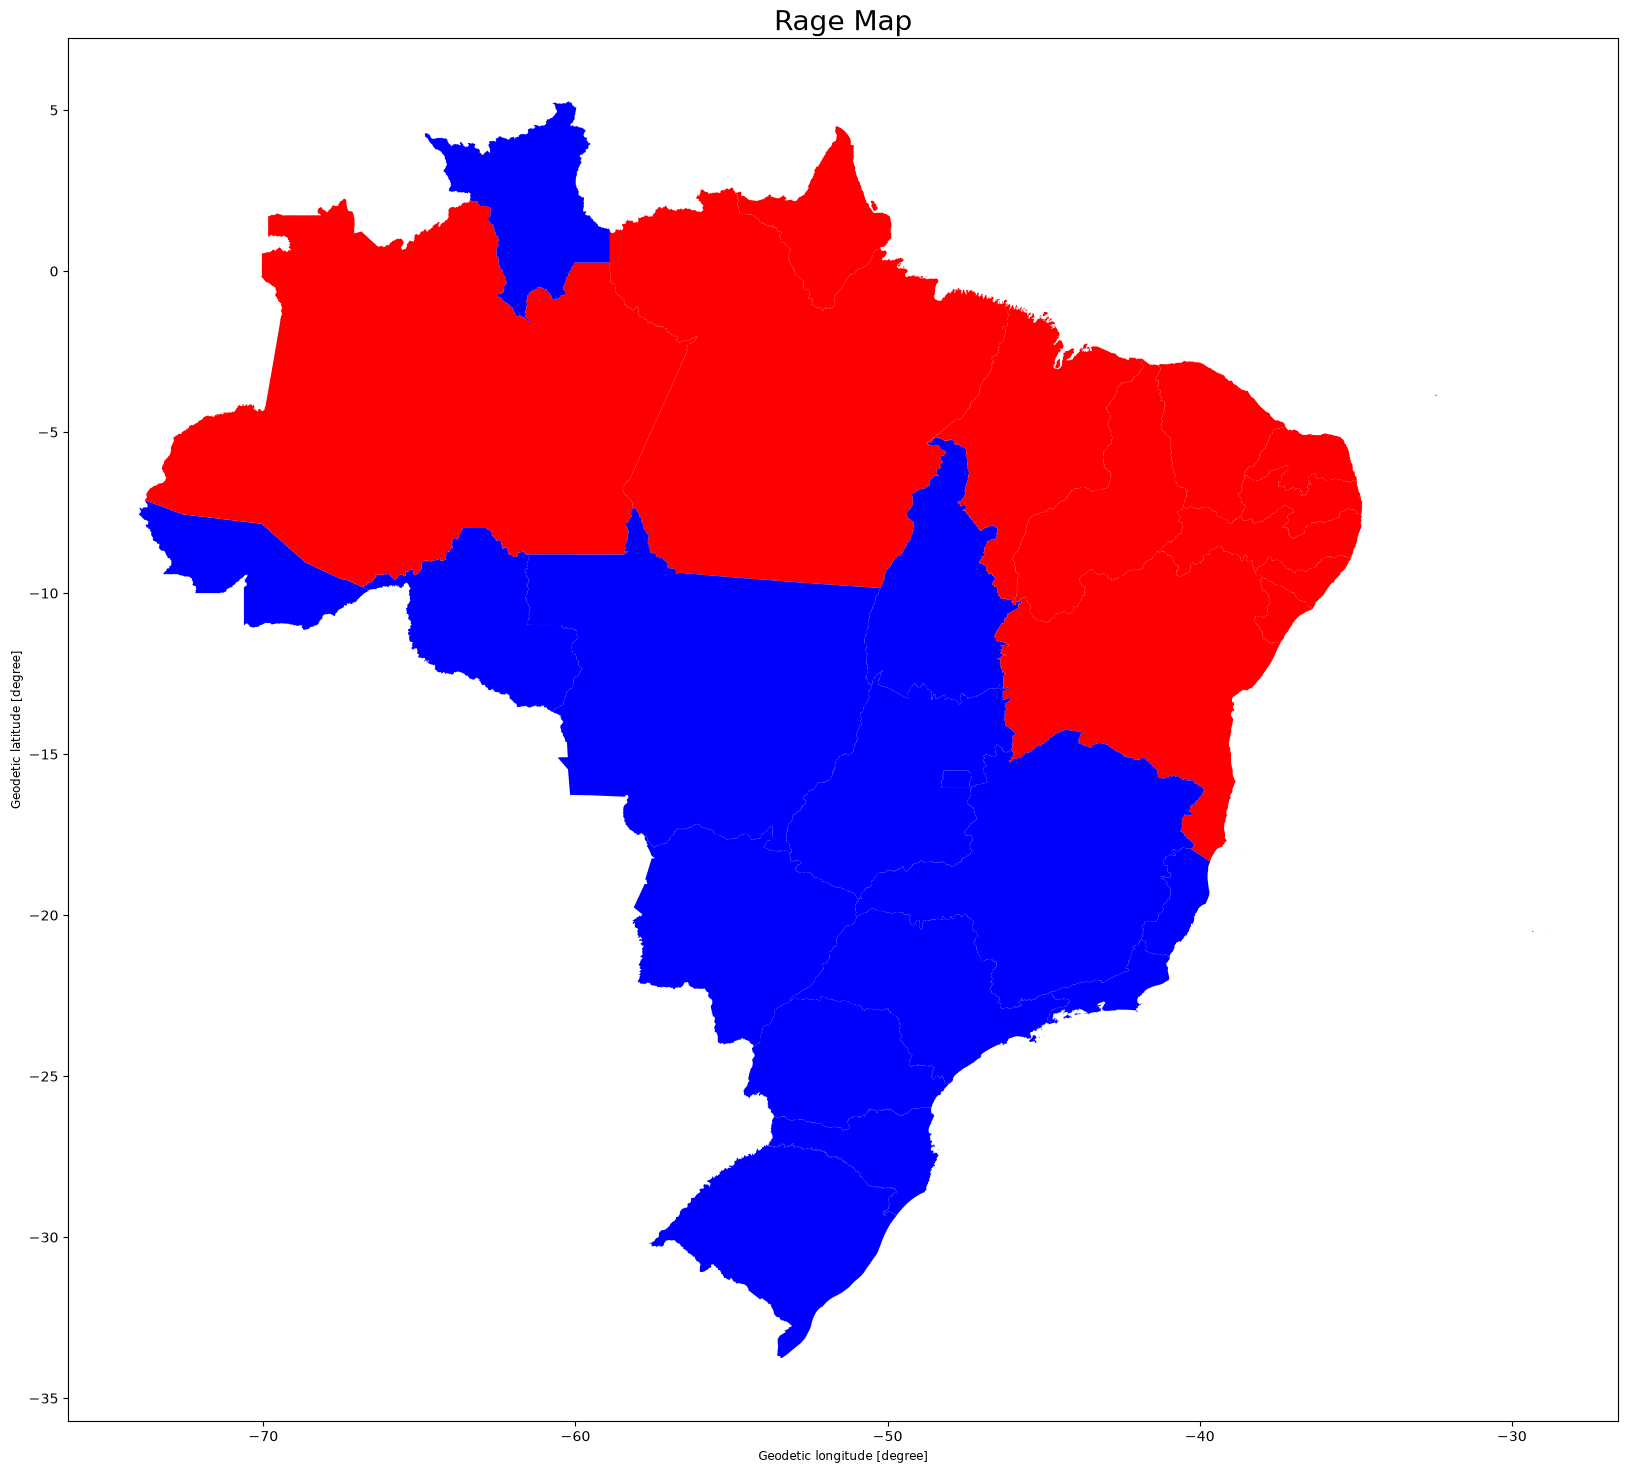

In [38]:
fig, ax = plt.subplots(figsize=(20,20))
mapa_uf_vot.plot(column='13_bin', color=mapa_uf_vot['13_color'], figsize=(10,10), ax=ax)
# ax.set_axis_off();
ax.set_title("Rage Map", fontsize=20)
plt.savefig('rage_map.pdf')

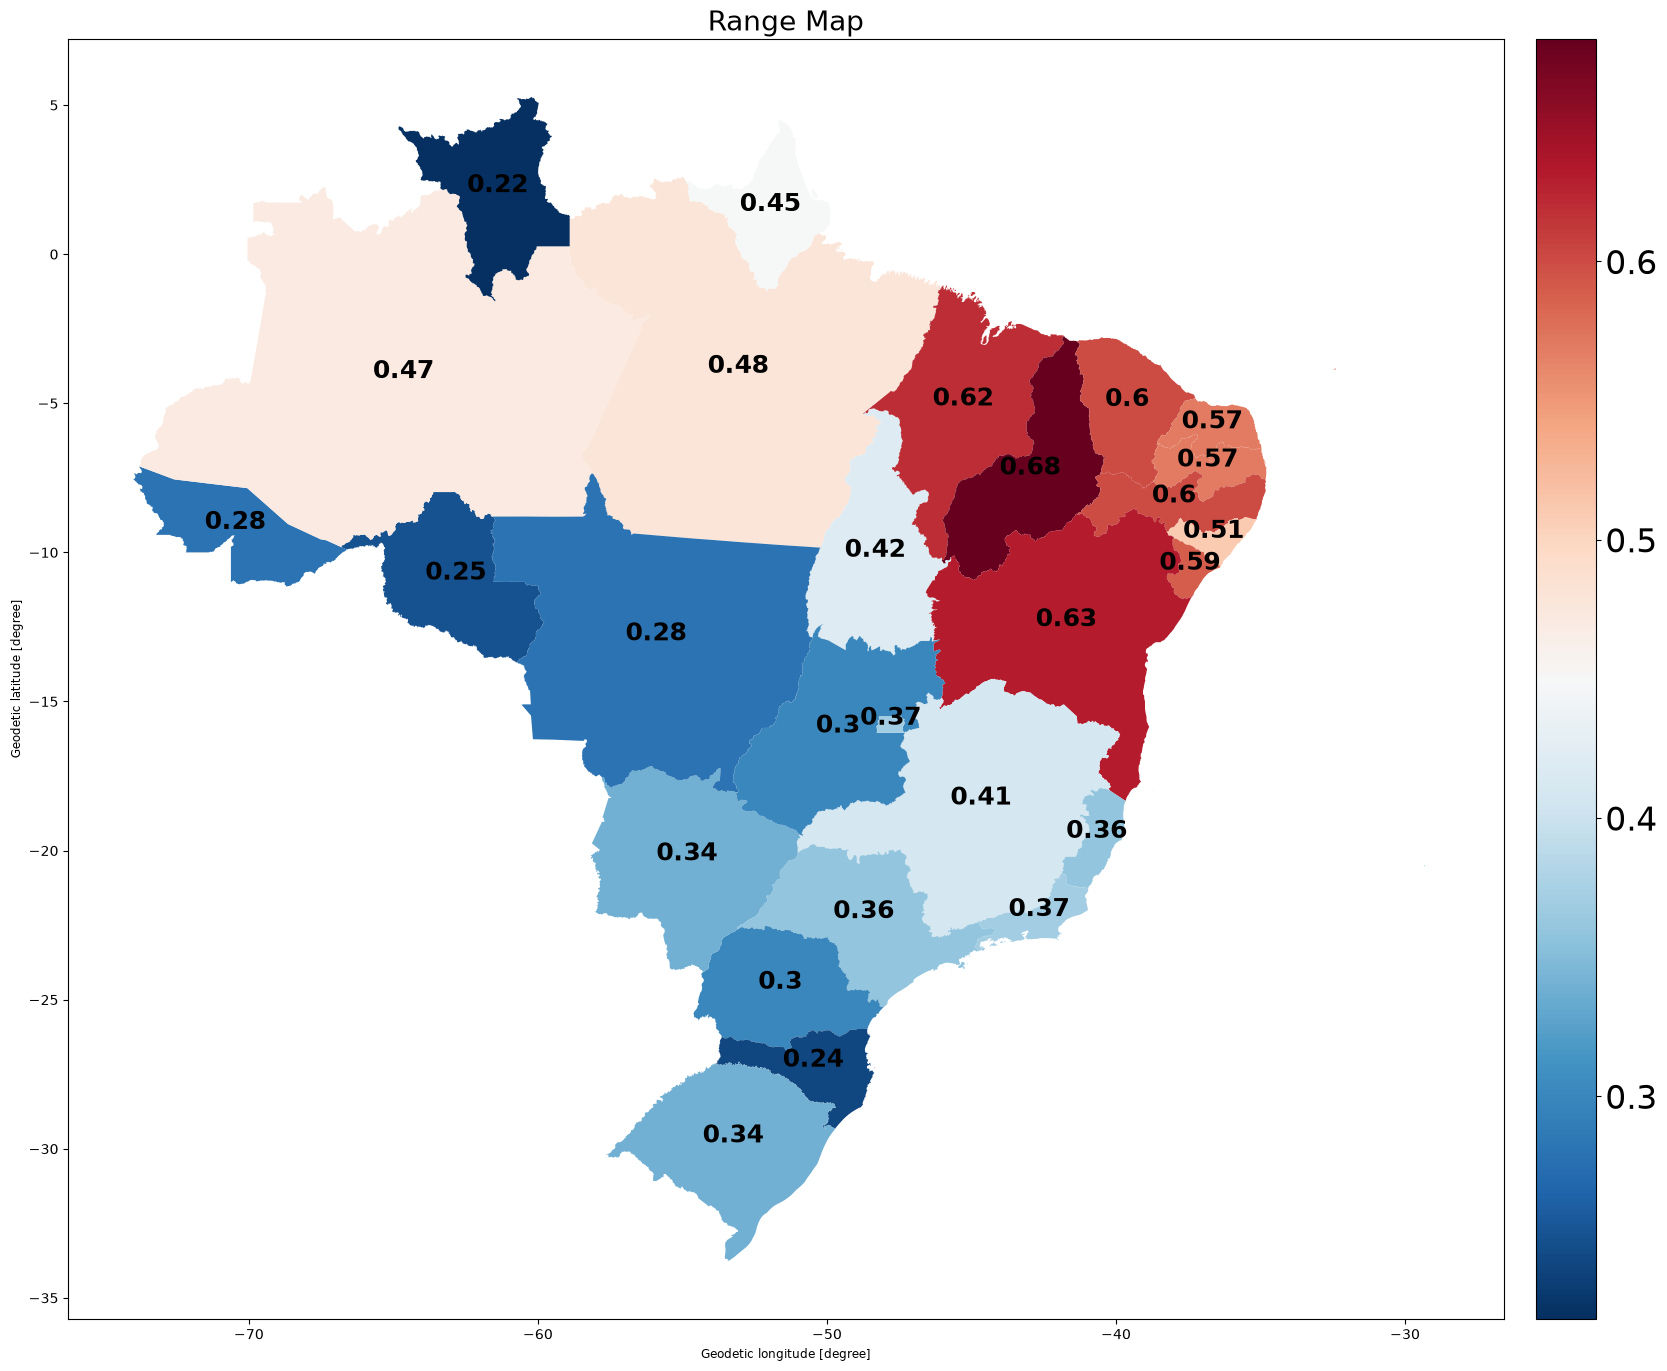

In [39]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
fig, ax = plt.subplots(figsize=(20,20))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.1)
mapa_uf_vot.plot(column='13r', cmap='RdBu_r', figsize=(10,10), legend=True, ax=ax, cax=cax)
mapa_uf_vot.apply(lambda x: ax.annotate(text=x['13r'], xy=x.geometry.centroid.coords[0], ha='center', color='black', fontsize=18, fontweight='bold'), axis=1);
# ax.set_axis_off();
for t in cax.get_yticklabels():
   t.set_fontsize(24)
ax.set_title("Range Map", fontsize=20)
# ax.set_caption('teste')
plt.savefig('range_map.pdf')

  


In [40]:
print(len(mapa), len(vot_mun[:len(mapa)]))

5572 5572


In [41]:
mapa['ufmun'] = mapa['SIGLA']+mapa['NM_MUN']

In [42]:
vot_mun['ufmun'] = vot_mun['SG_UF']+vot_mun['NM_MUNICIPIO']

In [43]:
vot_mun.info()

<class 'pandas.DataFrame'>
RangeIndex: 5717 entries, 0 to 5716
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SG_UF         5717 non-null   str    
 1   CD_MUNICIPIO  5717 non-null   object 
 2   NM_MUNICIPIO  5717 non-null   str    
 3   13            5717 non-null   float64
 4   14            5687 non-null   float64
 5   16            3440 non-null   float64
 6   21            3539 non-null   float64
 7   22            5715 non-null   float64
 8   27            3692 non-null   float64
 9   28            1669 non-null   float64
 10  29            2244 non-null   float64
 11  30            5263 non-null   float64
 12  35            2572 non-null   float64
 13  55            5687 non-null   float64
 14  70            5696 non-null   float64
 15  80            4601 non-null   float64
 16  95            5681 non-null   float64
 17  96            5682 non-null   float64
 18  All           5717 non-null   float64
 

In [44]:
mapa_vot = mapa.merge(vot_mun, on='ufmun')

In [45]:
mapa_vot['13_bin'] = mapa_vot[13] > mapa_vot[22]

In [46]:
mapa_vot['13_color'] = mapa_vot['13_bin'].apply(lambda x: 'r' if x == True else 'b')

C:\Users\adria\AppData\Local\Temp\ipykernel_32540\2273405976.py:2: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  mapa_vot.plot(column='13_bin', color=mapa_vot['13_color'], edgecolor=mapa_vot['13_color'], ax=ax)


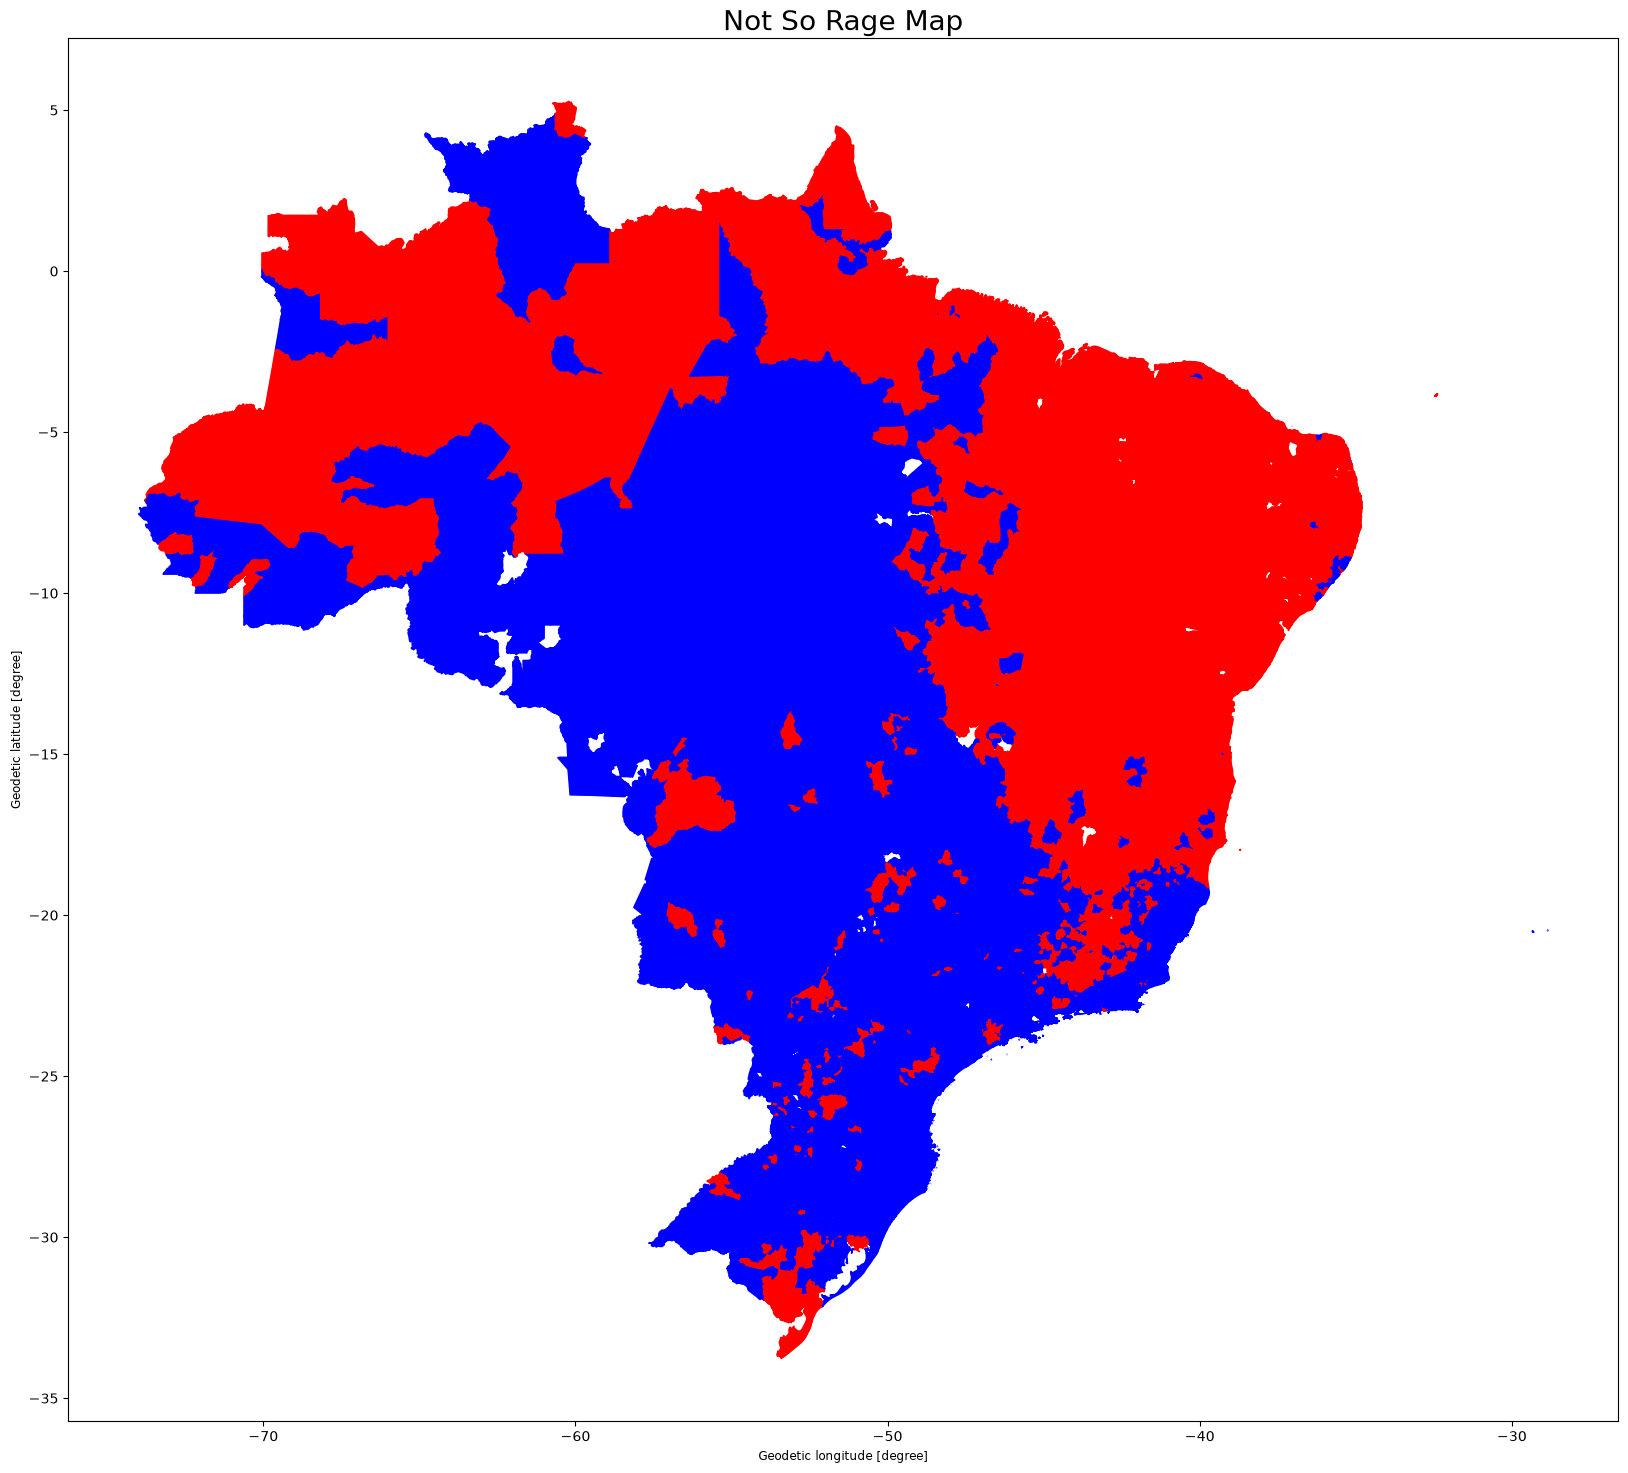

In [47]:
fig, ax = plt.subplots(figsize=(20,20))
mapa_vot.plot(column='13_bin', color=mapa_vot['13_color'], edgecolor=mapa_vot['13_color'], ax=ax)
# ax.set_axis_off();
ax.set_title("Not So Rage Map", fontsize=20)
plt.savefig('rage_map_mun.pdf')

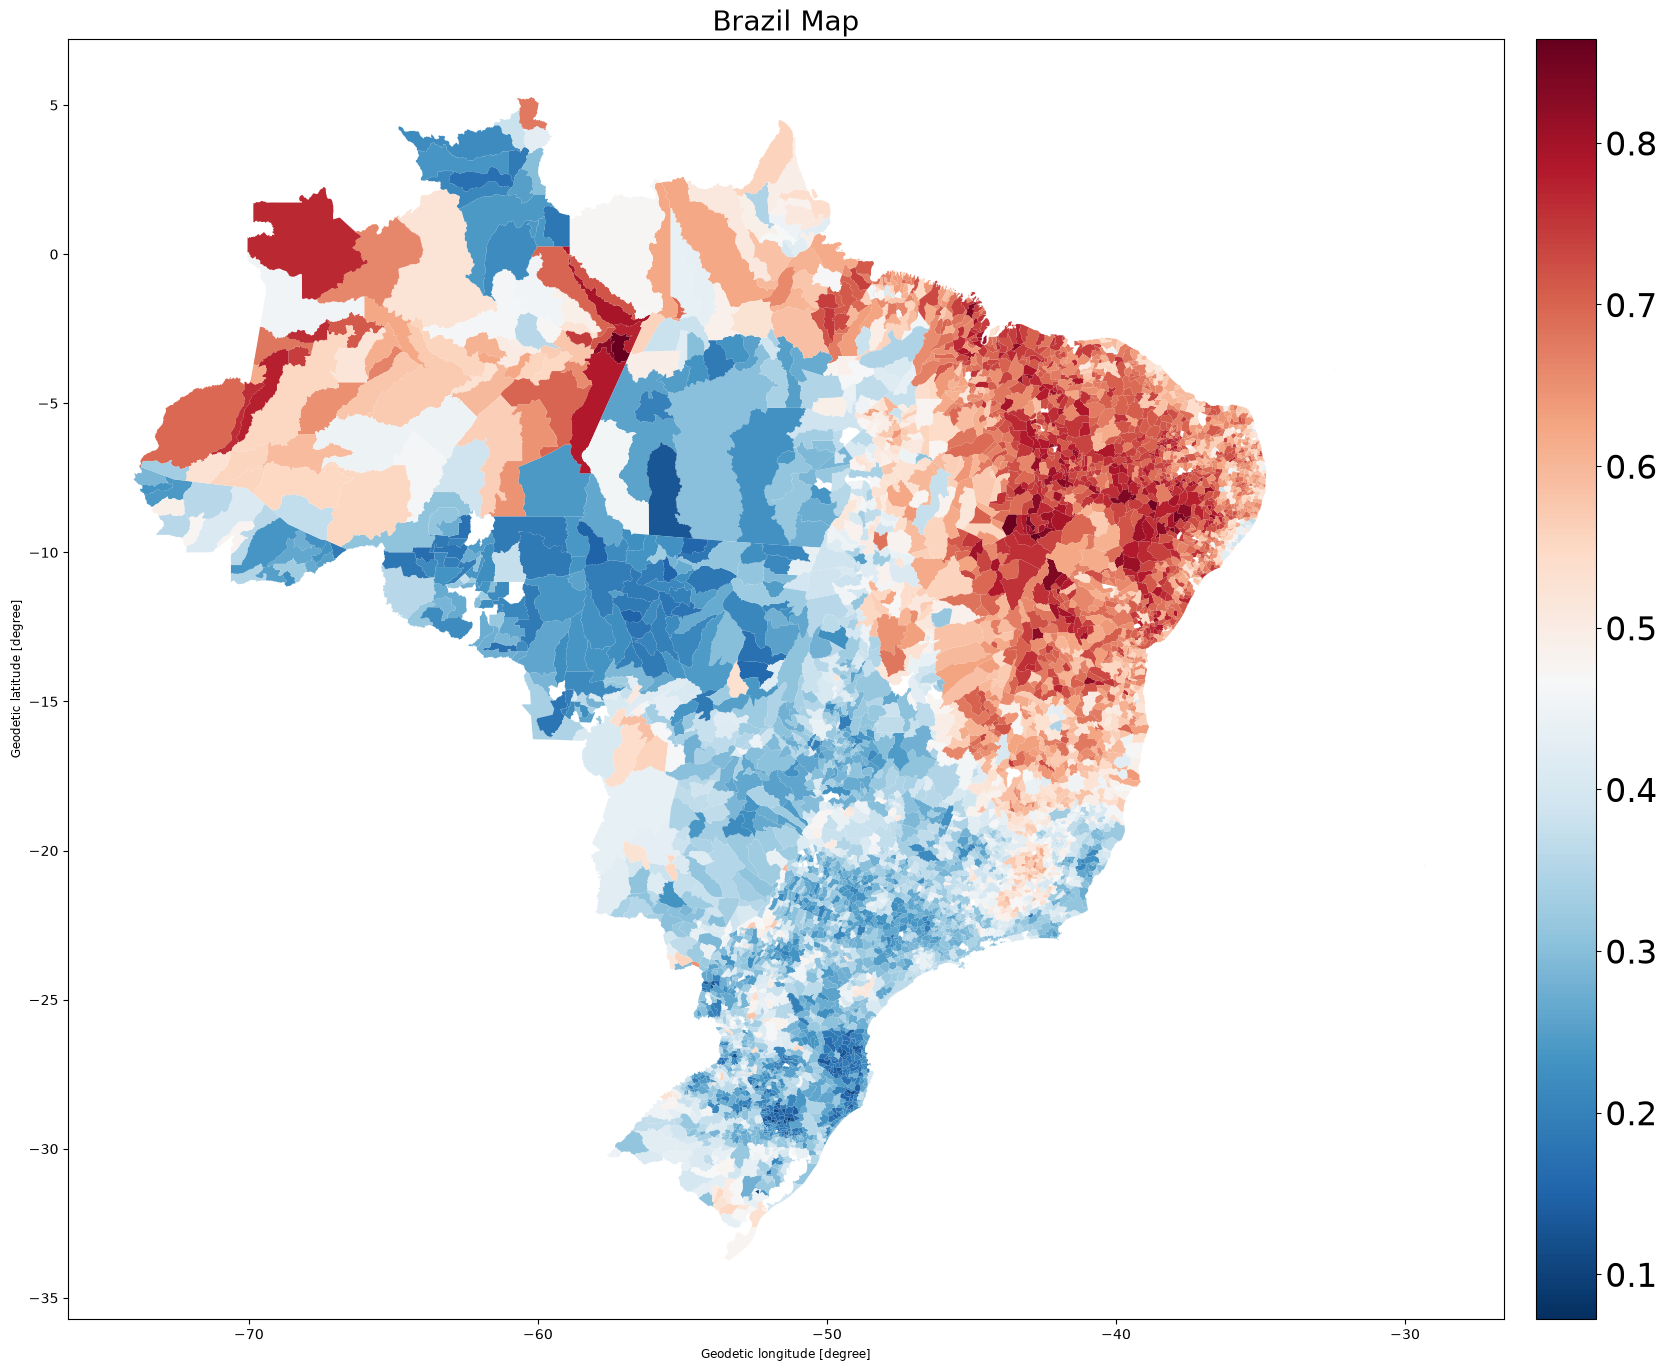

In [48]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
fig, ax = plt.subplots(figsize=(20,20))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.1)
mapa_vot.plot(column=13, cmap='RdBu_r', legend=True, edgecolor='none', ax=ax, cax=cax)
# mapa_vot.apply(lambda x: ax.annotate(text=x['13r'], xy=x.geometry.centroid.coords[0], ha='center', color='black', fontsize=18, fontweight='bold'), axis=1);
# ax.set_axis_off();
for t in cax.get_yticklabels():
   t.set_fontsize(24)
ax.set_title("Brazil Map", fontsize=20)
# ax.set_caption('teste')
plt.savefig('brazil_map.pdf')